# Mapas de sensores en DESlab

Reconstrucción del ejemplo de las páginas 4–13 de la presentación *Mapa de Sensores*: un sistema industrial
formado por una **válvula**, una **bomba** y un **controlador**, complementado con un sensor de flujo y uno de presión.
Al final se convierte el autómata con mapa sensorial en un autómata convencional.

In [1]:
#@title Instalación de DESlab desde GitHub (solo en Colab)
import shutil, subprocess

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q git+https://github.com/nebisman/deslab-py3.git

Note: you may need to restart the kernel to use updated packages.


In [2]:
from deslab import *

## 1. Válvula $V$

| Estados | | Eventos | |
|---|---|---|---|
| $VC$ | válvula cerrada | $ov$ | abrir válvula |
| $VO$ | válvula abierta | $cv$ | cerrar válvula |
| $SC$ | válvula obstruida cerrada | $so$ | falla de obstrucción con la válvula abierta |
| $SO$ | válvula obstruida abierta | $sc$ | falla de obstrucción con la válvula cerrada |

$so$ y $sc$ son los eventos de falla (no observables). Una válvula obstruida sigue recibiendo las órdenes $ov$ y $cv$
pero no cambia de estado, por eso $SC$ y $SO$ tienen autolazos en $ov$ y $cv$. Esos autolazos no están dibujados en
la diapositiva, pero son necesarios para obtener la composición de la página 7 (por ejemplo
$(SO,POFF,C1) \xrightarrow{ov} (SO,POFF,C2)$).

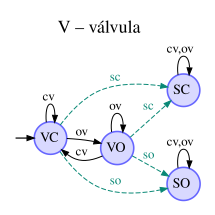

In [4]:
syms('VC VO SC SO ov cv so sc')
X = [VC, VO, SC, SO]
E = [ov, cv, so, sc]
T = [(VC, ov, VO), (VC, cv, VC), (VO, cv, VC), (VO, ov, VO),
     (VC, sc, SC), (VO, sc, SC), (VC, so, SO), (VO, so, SO),
     (SC, ov, SC), (SC, cv, SC), (SO, ov, SO), (SO, cv, SO)]

V = fsa(X, E, T, [VC], [], Sigobs= [ov,cv], name='$V$ -- válvula')
draw(V)

## 2. Bomba $B$

Estados $POFF$ (bomba apagada) y $PON$ (bomba encendida); eventos $pon$ (encender) y $poff$ (apagar).

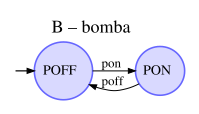

In [14]:
syms('POFF PON pon poff')
X1 = [POFF, PON]
E1 =  [pon, poff]
T1 = [(POFF, pon, PON), (PON, poff, POFF)]
B = fsa(X1,E1, T1, [POFF], [],  name='$B$ -- bomba')
draw(B)

## 3. Controlador $C$

El controlador opera en la secuencia: abrir válvula → prender bomba → apagar bomba → cerrar válvula.

En la celda se deja comentado un controlador alternativo con la secuencia
prender bomba → abrir válvula → cerrar válvula → apagar bomba.

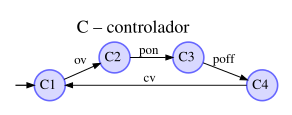

In [35]:
syms('C1 C2 C3 C4')
# controlador de la presentación: ov -> pon -> poff -> cv
C = fsa([C1, C2, C3, C4], [ov, pon, poff, cv],
        [(C1, ov, C2), (C2, pon, C3), (C3, poff, C4), (C4, cv, C1)], [C1], [],
        name='$C$ -- controlador')

# controlador alternativo: pon -> ov -> cv -> poff
# C = fsa([C1, C2, C3, C4], [ov, pon, poff, cv],
#         [(C1, pon, C2), (C2, ov, C3), (C3, cv, C4), (C4, poff, C1)], [C1], [],
#         name='$C$ -- controlador')
draw(C)

## 4. Composición paralela $G = V \| B \| C$

Los estados de la composición son tuplas anidadas `(('VO', 'PON'), 'C3')`; se renombran como `'VO,PON,C3'`
para que coincidan con la figura. Los eventos de falla $so$ y $sc$ son no observables.

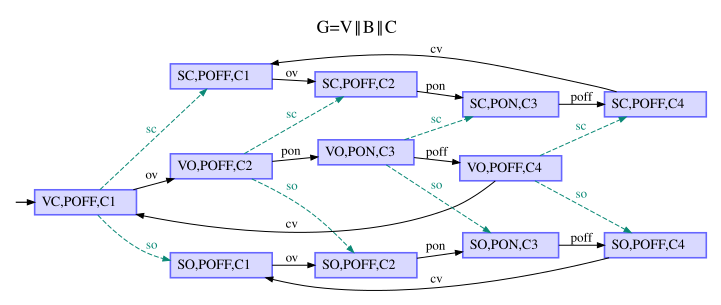

In [ ]:
G = V // B // C
G = G.renamestates({((v, b), c): '%s,%s,%s' % (v, b, c) for ((v, b), c) in G.X})
G = G.setpar(Sigobs=[ov, cv, pon, poff], name='$G = V \\| B \\| C$')
G.style='diagnoser'
draw(G)

## 5. Mapa sensorial

La información es complementada por dos sensores:

- Presión $S_2$: $PP$ (presión presente) / $NP$ (no hay presión presente)
- Flujo $S_1$: $F$ (hay flujo) / $NF$ (no hay flujo)

El mapa sensorial es un diccionario que asocia cada estado de $G$ con la lectura (presión, flujo).
Sólo cuando la bomba está encendida hay presión, y sólo hay flujo si además la válvula está abierta
($VO$ u obstruida abierta $SO$). Con el controlador $C$ de la presentación la bomba sólo está encendida en $C3$.

In [37]:
def lectura(x):
    v, b, c = x.split(',')
    if b == 'POFF':
        return ('NP', 'NF')
    return ('PP', 'F' if v in ('VO', 'SO') else 'NF')

Sensormap = {x: lectura(x) for x in G.X}

orden = sorted(G.X, key=lambda x: (x.split(',')[2], x))
print('%-4s %-14s %s' % ('No.', 'Estado', 'Lectura'))
for i, x in enumerate(orden, 1):
    print('%-4d %-14s %s' % (i, x, ','.join(Sensormap[x])))

No.  Estado         Lectura
1    SC,POFF,C1     NP,NF
2    SO,POFF,C1     NP,NF
3    VC,POFF,C1     NP,NF
4    SC,POFF,C2     NP,NF
5    SO,POFF,C2     NP,NF
6    VO,POFF,C2     NP,NF
7    SC,PON,C3      PP,NF
8    SO,PON,C3      PP,F
9    VO,PON,C3      PP,F
10   SC,POFF,C4     NP,NF
11   SO,POFF,C4     NP,NF
12   VO,POFF,C4     NP,NF


Autómata $G$ con las lecturas de los sensores escritas en cada estado (página 9):

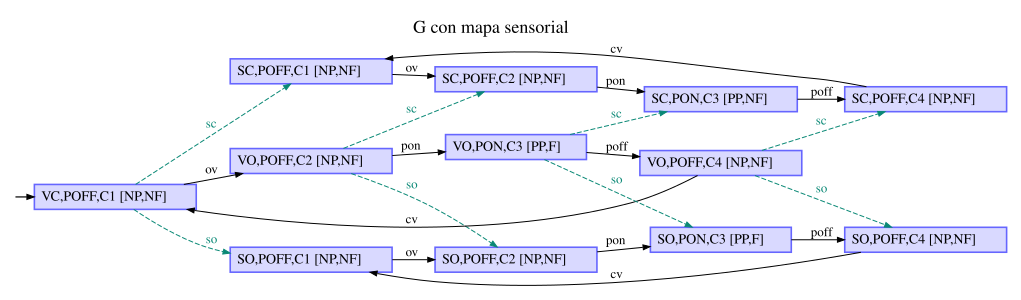

In [40]:
tabla = {x: '%s\\;[%s]' % (x, ','.join(Sensormap[x])) for x in G.X}
draw(G.setpar(table=tabla, name='$G$ con mapa sensorial'))

## 6. Conversión de un mapa sensorial a un autómata convencional

Sea $x \xrightarrow{e} y$ una transición de $G$ y $S_X$, $S_Y$ las lecturas de los sensores en $x$ e $y$.

- **Regla 1** ($e$ no observable, $S_X = S_Y$): se mantiene la transición $x \xrightarrow{e} y$.
- **Regla 2** ($e$ no observable, $S_X \neq S_Y$): los sensores reportan el cambio de estado; se crea un estado
  nuevo $x_{new}$ y se reemplaza por $x \xrightarrow{e} x_{new} \xrightarrow{S_X \to S_Y} y$, donde
  $S_X \to S_Y$ es un evento observable.
- **Regla 3** ($e$ observable): se usa la conversión de los autómatas de Moore,
  $x \xrightarrow{(e,\,S_Y)} y$.

La función `sensormap2fsa(G, S)` recibe el autómata `G` y el diccionario `S` que asocia cada estado de `G` con
la salida de los sensores (una tupla como `('NP', 'NF')` o una cadena). Los eventos no observables de `G` son
`G.Sigma - G.Sigobs`.

In [22]:
def sensormap2fsa(G, S, name=None):
    """Convierte el autómata G con mapa sensorial S (diccionario
    {estado: lectura de los sensores}) en un autómata convencional."""
    faltan = set(G.X) - set(S)
    if faltan:
        raise ValueError('Estados sin lectura de sensores: %s' % faltan)

    def lectura(s):
        return tuple(s) if isinstance(s, (tuple, list)) else (s,)

    Euo = G.Sigma - G.Sigobs
    X, E, Eobs, T, tabla = set(G.X), set(Euo), set(), [], {}
    for x, y, data in G.Graph.edges(data=True):
        e = data['label']
        if e in Euo and S[x] == S[y]:   # regla 1
            T.append((x, e, y))
        elif e in Euo:                  # regla 2
            n = len(tabla) + 1
            xnew = 'xnew%d' % n
            while xnew in X:
                xnew += "'"
            X.add(xnew)
           
            cambio = ','.join(lectura(S[x])) + '→' + ','.join(lectura(S[y]))
            T += [(x, e, xnew), (xnew, cambio, y)]
            E.add(cambio)
            Eobs.add(cambio)
        else:                           # regla 3
            ev = '(' + ','.join((e,) + lectura(S[y])) + ')'
            T.append((x, ev, y))
            E.add(ev)
            Eobs.add(ev)
    if name is None:
        name = G.name + ' -- convertido'
    return fsa(X, E, T, G.X0, G.Xm, tabla, Sigobs=Eobs, name=name)

## 7. Autómata convertido (página 13)

La única transición que cumple la regla 2 es la falla $sc$ desde $(VO,PON,C3)$: el flujo pasa de $F$ a $NF$,
lo que genera el estado $x_{new1}$ y el evento observable $PP,F \to PP,NF$. Las fallas $so$ y $sc$ restantes
no cambian la lectura de los sensores (regla 1) y todos los comandos del controlador se convierten con la regla 3.

Con el controlador alternativo (comentado en la sección 3), la regla 2 se aplica además a $so$ desde
$(VC,PON,C2)$ y desde $(VC,PON,C4)$, con el evento $PP,NF \to PP,F$.

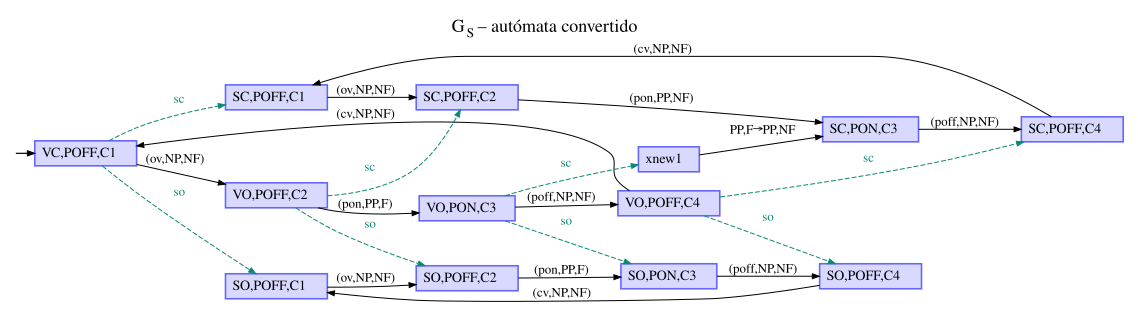

In [30]:
Gs = sensormap2fsa(G, Sensormap, name='$G_S$ -- autómata convertido')
Gs.style='diagnoser'
draw(Gs)


In [32]:
def verifydiagnosability(G, f):
    Euo = G.Sigma - G.Sigobs  # obtaining Sigma_uo
    # Step 1.1
    G_N1 = G.deletevent(f)
    # Step 1.2
    GN = ac(G_N1)
    # Step 2.1
    Al = labelfailaut(f)
    # Step 2.2
    Gl = G // Al
    Xml = [(x, l) for (x, l) in Gl.X if l == 'Y']
    Gl = Gl.setpar(Xm=Xml)
    # Step 2.3
    GY = coac(Gl)
    # Step 3
    R = [(event, event + '_R') for event in Euo]
    GN = renamevents(GN, R)
    # Step 4
    GV = GN // GY
    XmV = [(xN, (xY, l)) for (xN, (xY, l)) in GV.X if l == 'Y']
    GV = GV.setpar(Xm=XmV)
    GV.style='verifier'
   
    # Step 5

    # We need to find the nontrivial SCCs
    SCC = strconncomps(GV.Graph)
    C_1 = selfloopnodes(GV.Graph)
    SCC_NT = [C for C in SCC if (len(C) > 1)] + [set([C]) for C in C_1]

    # we are searching for a counter-example
    C1 = []
    diagnosable = True
    for C in SCC_NT:
        for x_V in (C & GV.Xm):
            if (GV.Gamma(x_V) & G.Sigma) != set([]):
                diagnosable = False
                if C1 != C:
                    print(C)
                C1 = C
    return diagnosable

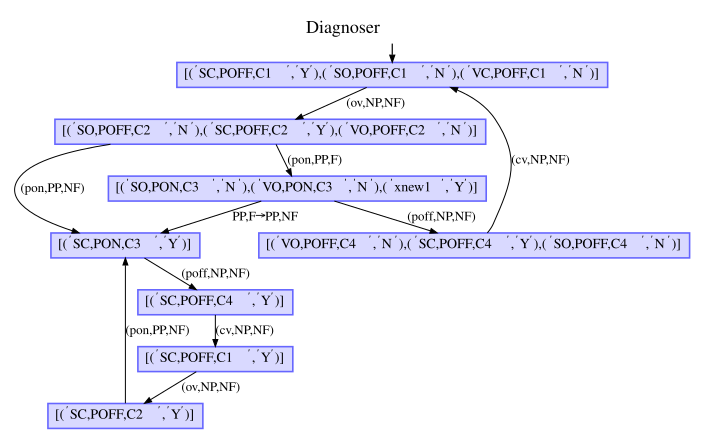

In [122]:
D1 = diagnoser(Gs,sc)
D2 = diagnoser(Gs,so)
for xD in D1.X:
    D1 = D1.renamestates([(xD, str(list(xD)))])

  

draw(D1)



